In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df=pd.read_csv('co2.csv')


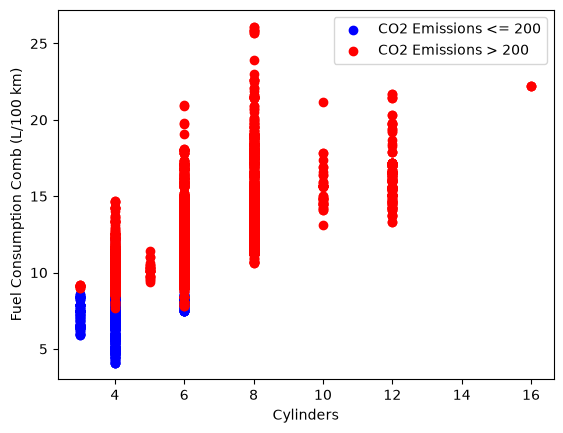

7385 2


In [77]:
y=(df['CO2 Emissions(g/km)']>200).astype(int).values
x=df[['Cylinders','Fuel Consumption Comb (L/100 km)']].values
m,n=x.shape
plt.scatter(x[y==0,0],x[y==0,1],color='blue',label='CO2 Emissions <= 200')
plt.scatter(x[y==1,0],x[y==1,1],color='red',label='CO2 Emissions > 200')
plt.xlabel('Cylinders')
plt.ylabel('Fuel Consumption Comb (L/100 km)')
plt.legend()
plt.show()
print(m,n)  

In [49]:
def sigmoid(z):
    return 1/(1+np.exp(-z))

In [50]:
def error(x,y,w,b):
    sum=0
    for i in range(m):
        z=np.dot(w,x[i])+b
        g=sigmoid(z)
        error=-(y[i]*np.log(g)+(1-y[i])*np.log(1-g))
        sum+=error
    return (sum/m)

In [52]:
def gradient(x,y,w,b):

    dw=np.zeros(n)
    db=0

    for i in range(m):
        z=np.dot(w,x[i])+b
        g=sigmoid(z)
        db+=(g-y[i])
        for j in range(n):
            dw[j]+=(g-y[i])*x[i,j]

    db=db/m
    dw=dw/m

    return dw,db

In [ ]:
def gradientD(x,y,A,its):
    w=np.zeros(n)
    b=0
    for i in range(its):
        dw,db=gradient(x,y,w,b)
        w=w-A*dw
        b=b-A*db
        if i%1000==0:
            print(f"Iteration {i}: Error={error(x,y,w,b)}")
    return w,b

In [39]:
def predict(x,w,b):
    pred=np.zeros(m)
    for i in range(m):
        z=np.dot(w,x[i])+b
        g=sigmoid(z)
        if g>=0.5:
            pred[i]=1
        else:
            pred[i]=0
    return pred

In [78]:
A=0.01
its=20000
fw,fb = gradientD(x,y,A,its)
predictions=predict(x,fw,fb)
acc=np.mean(predictions==y)*100
print(acc)



Iteration 0: Error=0.5416501264801572
Iteration 1000: Error=0.40552930462782144
Iteration 2000: Error=0.3847115995955842
Iteration 3000: Error=0.3667309586671738
Iteration 4000: Error=0.3509648708420687
Iteration 5000: Error=0.3370386930646367
Iteration 6000: Error=0.32466137953015783
Iteration 7000: Error=0.31359640992371113
Iteration 8000: Error=0.30364983413605534
Iteration 9000: Error=0.2946619071879338
Iteration 10000: Error=0.28650047857273875
Iteration 11000: Error=0.27905569385069784
Iteration 12000: Error=0.27223575573612363
Iteration 13000: Error=0.2659635399834039
Iteration 14000: Error=0.26017389461029794
Iteration 15000: Error=0.2548114816111972
Iteration 16000: Error=0.24982904770893755
Iteration 17000: Error=0.2451860339973717
Iteration 18000: Error=0.2408474534453326
Iteration 19000: Error=0.23678298055122576
89.9796885578876


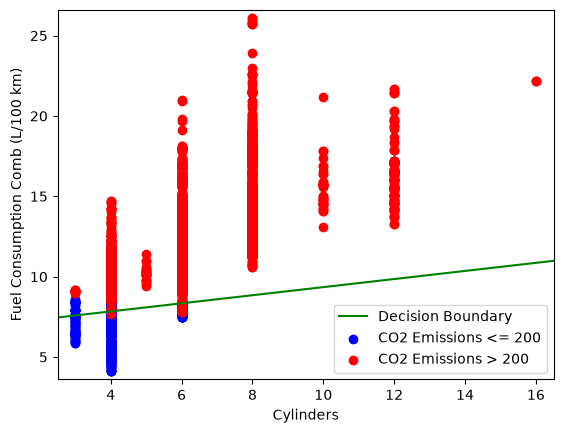

In [79]:
q=-fw[0]/fw[1]
c=-fb/fw[1]
xmin,xmax=x[:,0].min()-0.5,x[:,0].max()+0.5
ymin,ymax=x[:,1].min()-0.5,x[:,1].max()+0.5
x1=np.linspace(xmin,xmax,100)
y1=q*x1+c
plt.plot(x1,y1,color='green',label='Decision Boundary')
plt.scatter(x[y==0,0],x[y==0,1],color='blue',label='CO2 Emissions <= 200')
plt.scatter(x[y==1,0],x[y==1,1],color='red',label='CO2 Emissions > 200')
plt.xlabel('Cylinders')
plt.ylabel('Fuel Consumption Comb (L/100 km)')
plt.xlim(xmin,xmax)
plt.ylim(ymin,ymax)
plt.legend()
plt.show()